## Imports ##

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, multilabel_confusion_matrix)
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, TransformerMixin
from scipy.stats import chi2_contingency
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score
import numpy as np

## Fetch UCI Car_Evaluation Dataset ##

In [2]:
# fetch dataset 
car_evaluation = fetch_ucirepo(id=19) 
  
# data (as pandas dataframes) 
X = car_evaluation.data.features 
y = car_evaluation.data.targets 
  
# metadata 
print(car_evaluation.metadata) 
  
# variable information 
print(car_evaluation.variables) 

{'uci_id': 19, 'name': 'Car Evaluation', 'repository_url': 'https://archive.ics.uci.edu/dataset/19/car+evaluation', 'data_url': 'https://archive.ics.uci.edu/static/public/19/data.csv', 'abstract': 'Derived from simple hierarchical decision model, this database may be useful for testing constructive induction and structure discovery methods.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1728, 'num_features': 6, 'feature_types': ['Categorical'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1988, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5JP48', 'creators': ['Marko Bohanec'], 'intro_paper': {'ID': 249, 'type': 'NATIVE', 'title': 'Knowledge acquisition and explanation for multi-attribute decision making', 'authors': 'M. Bohanec, V. Rajkovič', 'venue': '8th Intl Workshop on Expert Systems and their Applications, 

## Identify Dataset Metadata & Visualisation ##

In [3]:
# Dataset summary and integrity audit against the UCI specification.
expected_features = ["buying", "maint", "doors", "persons", "lug_boot", "safety"]
expected_categories = {
    "buying": {"vhigh", "high", "med", "low"},
    "maint": {"vhigh", "high", "med", "low"},
    "doors": {"2", "3", "4", "5more"},
    "persons": {"2", "4", "more"},
    "lug_boot": {"small", "med", "big"},
    "safety": {"low", "med", "high"},
}
target_order = ["unacc", "acc", "good", "vgood"]
colors = {
    "unacc": "#C20303",
    "acc": "#FFC400",
    "good": "#59A14F",
    "vgood": "#2FF4A2",
}
target = y.squeeze()

metadata_summary = pd.DataFrame({
    "Data type": X.dtypes.astype(str),
    "Unique values": X.nunique(dropna=True),
    "Missing values": X.isna().sum(),
})
display(metadata_summary)

# Build one compact report covering missingness, schema, values, and label consistency.
audit = []
def add_check(check, status, details):
    audit.append({"Check": check, "Status": status, "Details": details})

add_check("Dataset size", "PASS" if len(X) == 1728 else "REVIEW", f"{len(X)} rows (UCI reference: 1728)")
add_check("Expected feature columns", "PASS" if list(X.columns) == expected_features else "REVIEW", f"Observed: {list(X.columns)}")
add_check("Categorical feature types", "PASS" if all(pd.api.types.is_object_dtype(dtype) or isinstance(dtype, pd.CategoricalDtype) for dtype in X.dtypes) else "REVIEW", ", ".join(f"{col}: {dtype}" for col, dtype in X.dtypes.items()))
add_check("Missing feature values", "PASS" if not X.isna().any().any() else "REVIEW", f"{int(X.isna().sum().sum())} missing cells")
add_check("Missing target values", "PASS" if not target.isna().any() else "REVIEW", f"{int(target.isna().sum())} missing labels")
add_check("Duplicate feature rows", "PASS" if not X.duplicated().any() else "REVIEW", f"{int(X.duplicated().sum())} duplicate rows")

for column, expected in expected_categories.items():
    if column not in X.columns:
        add_check(f"Values in {column}", "REVIEW", "Expected feature column is missing")
        continue
    observed = set(X[column].dropna().astype(str).unique())
    unexpected = sorted(observed - expected)
    absent = sorted(expected - observed)
    status = "REVIEW" if unexpected or absent else "PASS"
    add_check(f"Values in {column}", status, f"Unexpected: {unexpected}; documented but not observed: {absent}")

expected_target_labels = set(target_order)
observed_targets = set(target.dropna().astype(str).unique())
unexpected_targets = sorted(observed_targets - expected_target_labels)
absent_targets = sorted(expected_target_labels - observed_targets)
add_check("Target labels", "REVIEW" if unexpected_targets or absent_targets else "PASS", f"Unexpected: {unexpected_targets}; documented but not observed: {absent_targets}")

if set(expected_features).issubset(X.columns):
    rows_with_target = X[expected_features].reset_index(drop=True).copy()
    rows_with_target["target"] = target.reset_index(drop=True)
    labels_per_feature_row = rows_with_target.groupby(expected_features, dropna=False)["target"].nunique()
    conflicting_rows = int((labels_per_feature_row > 1).sum())
    add_check("Conflicting labels for identical feature rows", "PASS" if conflicting_rows == 0 else "REVIEW", f"{conflicting_rows} feature combinations have multiple labels")

constant_features = X.columns[X.nunique(dropna=False) <= 1].tolist()
add_check("Constant features", "PASS" if not constant_features else "REVIEW", f"{constant_features}")
display(pd.DataFrame(audit))

# Show the target distribution in the same explicit class order.
target_counts = target.value_counts().reindex(target_order, fill_value=0)
display(pd.DataFrame({"Count": target_counts, "Proportion": (target_counts / len(target)).round(3)}))

,Data type,Unique values,Missing values
buying,str,4,0
maint,str,4,0
doors,str,4,0
persons,str,3,0
lug_boot,str,3,0
safety,str,3,0


,Check,Status,Details
0,Dataset size,PASS,1728 rows (UCI reference: 1728)
1,Expected feature columns,PASS,"Observed: ['buying', 'maint', 'doors', 'person..."
2,Categorical feature types,REVIEW,"buying: str, maint: str, doors: str, persons: ..."
3,Missing feature values,PASS,0 missing cells
4,Missing target values,PASS,0 missing labels
5,Duplicate feature rows,PASS,0 duplicate rows
6,Values in buying,PASS,Unexpected: []; documented but not observed: []
7,Values in maint,PASS,Unexpected: []; documented but not observed: []
8,Values in doors,PASS,Unexpected: []; documented but not observed: []
9,Values in persons,PASS,Unexpected: []; documented but not observed: []


,Count,Proportion
class,,
unacc,1210,0.700
acc,384,0.222
good,69,0.040
vgood,65,0.038


In [4]:
# Hold out 40% for final testing before plotting target relationships or tuning models.
y_1d = y.squeeze()
X_train, X_test, y_train, y_test = train_test_split(
    X, y_1d, test_size=0.40, random_state=42, stratify=y_1d
)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")

Training rows: 1036 | Test rows: 692


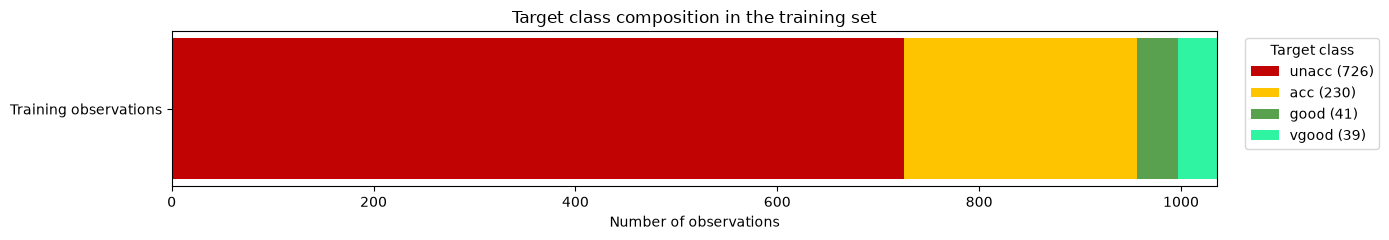

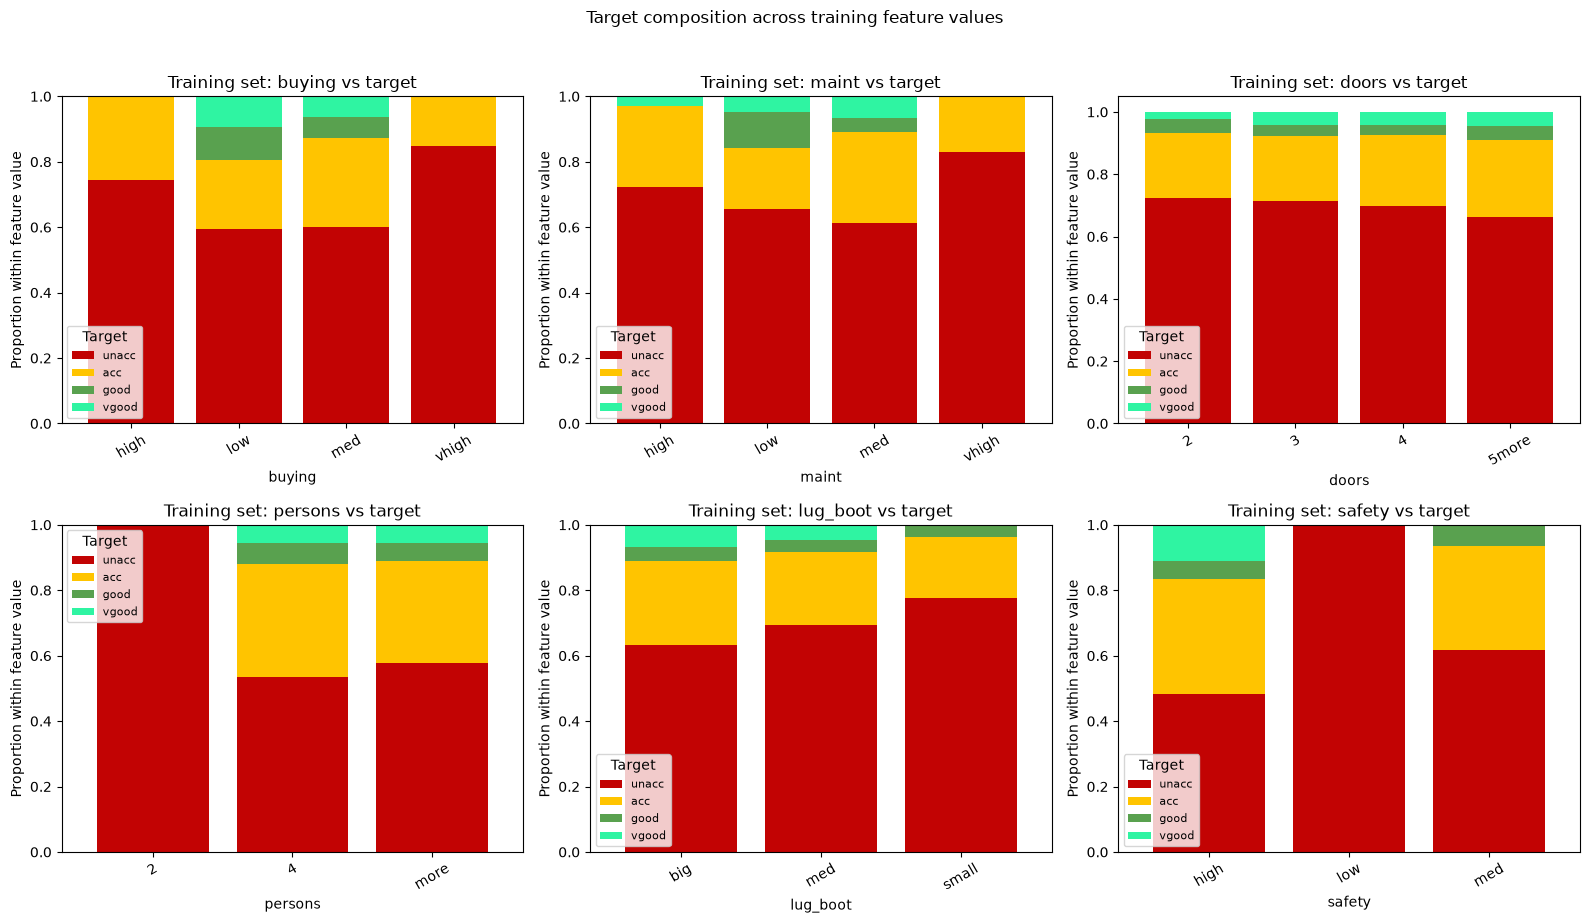

In [5]:
# Training target composition, ordered from unacc to vgood.
train_target_counts = y_train.value_counts().reindex(target_order, fill_value=0)
fig, ax = plt.subplots(figsize=(14, 2.5))
left = 0
for label in target_order:
    count = int(train_target_counts[label])
    ax.barh("Training observations", count, left=left, color=colors[label], label=f"{label} ({count})")
    left += count
ax.set_xlim(0, len(y_train))
ax.set_title("Target class composition in the training set")
ax.set_xlabel("Number of observations")
ax.legend(title="Target class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Within each feature value, show the target proportions in the training set.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feature in zip(axes.flat, expected_features):
    proportions = pd.crosstab(X_train[feature], y_train, normalize="index")
    proportions = proportions.reindex(columns=target_order, fill_value=0).sort_index()
    proportions.plot(kind="bar", stacked=True, ax=ax,
                     color=[colors[label] for label in target_order], width=0.8)
    ax.set_title(f"Training set: {feature} vs target")
    ax.set_xlabel(feature)
    ax.set_ylabel("Proportion within feature value")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Target", fontsize=8)
fig.suptitle("Target composition across training feature values", y=1.02)
plt.tight_layout()
plt.show()

## Model Setup, Nested CV & Hyperparameter Search ##

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),
    "SVM": SVC(random_state=1),
    "Decision Tree": DecisionTreeClassifier(random_state=1),
    "MLP": MLPClassifier(max_iter=2000, random_state=1),
}

def make_categorical_pipeline(model, selector=None):
    """Apply optional feature selection, one-hot encoding, then fit a classifier."""
    steps = []
    if selector is not None:
        steps.append(selector)
    steps.extend([OneHotEncoder(handle_unknown="ignore"), model])
    return make_pipeline(*steps)

# Search spaces are intentionally compact for this categorical dataset.
parameter_grids = {
    "Logistic Regression": {
        "logisticregression__C": [0.1, 0.2, 0.5, 1.0, 5.0, 10.0],
    },
    "SVM": {
        "svc__C": [0.1, 1.0, 10.0],
        "svc__kernel": ["linear", "rbf"],
        "svc__gamma": ["scale", "auto"],
    },
    "Decision Tree": {
        "decisiontreeclassifier__max_depth": [3, 5, 10, 15],
        "decisiontreeclassifier__min_samples_leaf": [1, 2, 4],
    },
    "MLP": {
        "mlpclassifier__hidden_layer_sizes": [(50,), (100,), (100, 50)],
        "mlpclassifier__alpha": [0.0001, 0.001],
        "mlpclassifier__learning_rate_init": [0.001, 0.01],
    },
}

In [7]:
# Nested CV estimates the full tuning procedure using training data only.
# Outer folds estimate performance; each inner GridSearchCV selects hyperparameters.
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
scoring = {"macro_f1": "f1_macro", "accuracy": "accuracy"}
nested_results = []

for name, estimator in models.items():
    inner_search = GridSearchCV(
        estimator=make_categorical_pipeline(estimator),
        param_grid=parameter_grids[name],
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
    )
    outer_scores = cross_validate(
        inner_search,
        X_train,
        y_train,
        cv=outer_cv,
        scoring=scoring,
        n_jobs=1,  # Avoid nested parallel-job oversubscription.
        return_train_score=False,
    )
    nested_results.append({
        "Model": name,
        "Nested CV macro F1": outer_scores["test_macro_f1"].mean(),
        "Macro F1 std": outer_scores["test_macro_f1"].std(),
        "Nested CV accuracy": outer_scores["test_accuracy"].mean(),
        "Accuracy std": outer_scores["test_accuracy"].std(),
    })

nested_cv_results = pd.DataFrame(nested_results).sort_values(
    "Nested CV macro F1", ascending=False
)
display(nested_cv_results)

# After nested evaluation, tune once on all training data and refit each best pipeline.
# These final fitted estimators are the ones evaluated on the held-out test set.
search_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=202)
searches = {}
search_summary = []
for name, estimator in models.items():
    search = GridSearchCV(
        estimator=make_categorical_pipeline(estimator),
        param_grid=parameter_grids[name],
        scoring="f1_macro",
        cv=search_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    best_index = search.best_index_
    search_summary.append({
        "Model": name,
        "Mean training fold macro F1": search.cv_results_["mean_train_score"][best_index],
        "Best inner CV macro F1": search.best_score_,
        "CV std": search.cv_results_["std_test_score"][best_index],
        "Best parameters": search.best_params_,
    })

training_search_results = pd.DataFrame(search_summary).sort_values(
    "Best inner CV macro F1", ascending=False
)
display(training_search_results)
best_estimators = {name: search.best_estimator_ for name, search in searches.items()}

,Model,Nested CV macro F1,Macro F1 std,Nested CV accuracy,Accuracy std
1,SVM,0.963899,0.028917,0.987467,0.009901
3,MLP,0.962497,0.019981,0.987449,0.004932
2,Decision Tree,0.875158,0.041726,0.953670,0.007218
0,Logistic Regression,0.852042,0.022653,0.919867,0.016964


,Model,Mean training fold macro F1,Best inner CV macro F1,CV std,Best parameters
1,SVM,1.000000,0.975524,0.021360,"{'svc__C': 10.0, 'svc__gamma': 'scale', 'svc__..."
3,MLP,1.000000,0.971015,0.017532,"{'mlpclassifier__alpha': 0.0001, 'mlpclassifie..."
2,Decision Tree,1.000000,0.912880,0.034885,"{'decisiontreeclassifier__max_depth': 15, 'dec..."
0,Logistic Regression,0.897363,0.833437,0.029129,{'logisticregression__C': 10.0}


In [8]:
# Evaluate each best, training-refitted pipeline on the held-out test set once.
# TP/FP/TN/FN are calculated one class vs all other classes.
test_results = []
class_count_results = []
for name, estimator in best_estimators.items():
    predictions = estimator.predict(X_test)
    test_results.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "Test macro F1": f1_score(y_test, predictions, average="macro"),
        "Test weighted F1": f1_score(y_test, predictions, average="weighted"),
    })

    print(f"\n{name}: held-out test set")
    print(classification_report(y_test, predictions, labels=target_order, zero_division=0))

    class_matrices = multilabel_confusion_matrix(
        y_test, predictions, labels=target_order
    )
    for label, matrix in zip(target_order, class_matrices):
        tn, fp, fn, tp = matrix.ravel()
        specificity = tn / (tn + fp) if (tn + fp) else float("nan")
        class_count_results.append({
            "Model": name,
            "Class (positive)": label,
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
            "Specificity": specificity,
        })

test_results_df = pd.DataFrame(test_results).sort_values(
    "Test macro F1", ascending=False
)
display(test_results_df)

display(pd.DataFrame(class_count_results))


Logistic Regression: held-out test set
              precision    recall  f1-score   support

       unacc       0.96      0.96      0.96       484
         acc       0.84      0.86      0.85       154
        good       0.95      0.64      0.77        28
       vgood       0.81      0.96      0.88        26

    accuracy                           0.93       692
   macro avg       0.89      0.86      0.86       692
weighted avg       0.93      0.93      0.93       692


SVM: held-out test set
              precision    recall  f1-score   support

       unacc       1.00      1.00      1.00       484
         acc       0.99      1.00      0.99       154
        good       0.96      0.96      0.96        28
       vgood       1.00      0.96      0.98        26

    accuracy                           1.00       692
   macro avg       0.99      0.98      0.98       692
weighted avg       1.00      1.00      1.00       692


Decision Tree: held-out test set
              precision    recal

,Model,Test accuracy,Test balanced accuracy,Test macro F1,Test weighted F1
3,MLP,0.992775,0.996311,0.994685,0.992798
1,SVM,0.995665,0.980940,0.984298,0.995659
2,Decision Tree,0.968208,0.936081,0.930000,0.968375
0,Logistic Regression,0.926301,0.856087,0.863029,0.925667


,Model,Class (positive),TP,FP,TN,FN,Specificity
0,Logistic Regression,unacc,466,18,190,18,0.913462
1,Logistic Regression,acc,132,26,512,22,0.951673
2,Logistic Regression,good,18,1,663,10,0.998494
3,Logistic Regression,vgood,25,6,660,1,0.990991
4,SVM,unacc,483,0,208,1,1.000000
5,SVM,acc,154,2,536,0,0.996283
6,SVM,good,27,1,663,1,0.998494
7,SVM,vgood,25,0,666,1,1.000000
8,Decision Tree,unacc,474,4,204,10,0.980769
9,Decision Tree,acc,147,12,526,7,0.977695


## Visualize CV and test results

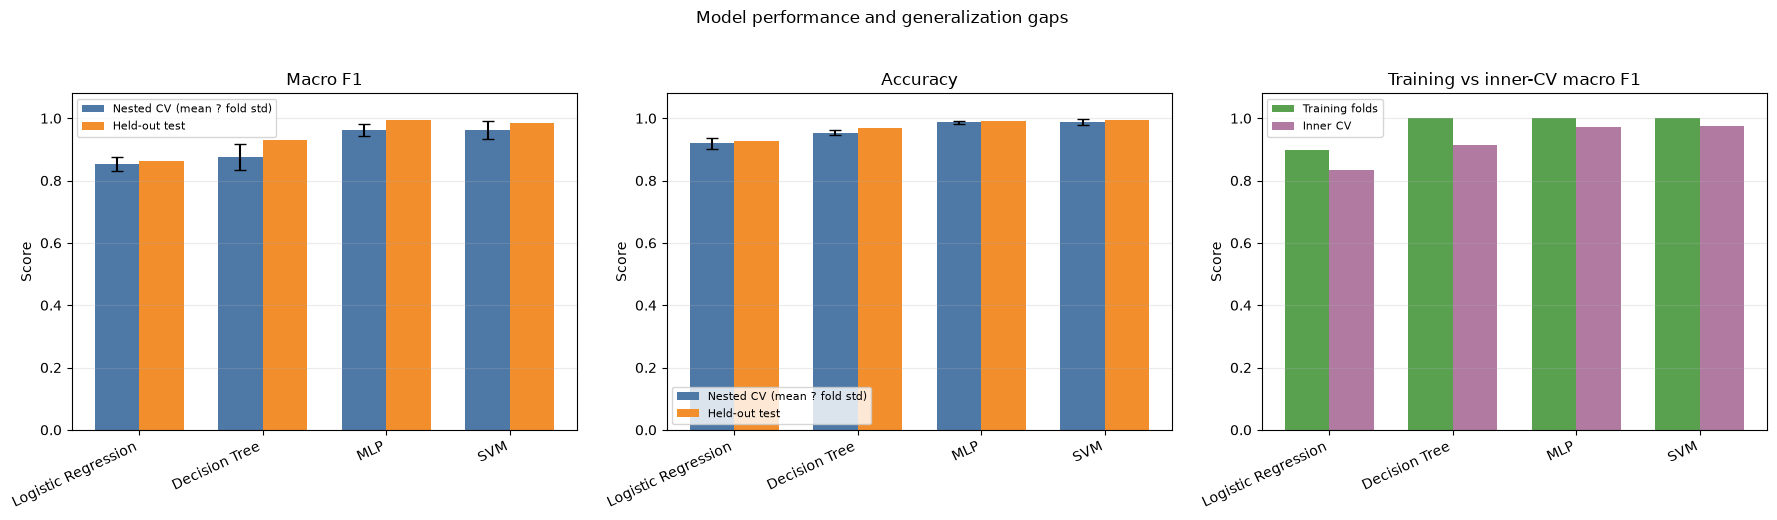

In [9]:
# Join the nested-CV, training-search, and one-time test summaries by model.
comparison = (
    nested_cv_results
    .merge(test_results_df, on="Model")
    .merge(
        training_search_results[["Model", "Mean training fold macro F1", "Best inner CV macro F1"]],
        on="Model",
    )
    .sort_values("Nested CV macro F1", ascending=True)
    .reset_index(drop=True)
)

models_ordered = comparison["Model"]
x = np.arange(len(models_ordered))
bar_width = 0.36
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Nested-CV bars include outer-fold standard deviation. Test bars are one held-out split.
axes[0].bar(
    x - bar_width / 2, comparison["Nested CV macro F1"], bar_width,
    yerr=comparison["Macro F1 std"], capsize=4,
    label="Nested CV (mean ? fold std)", color="#4E79A7",
)
axes[0].bar(
    x + bar_width / 2, comparison["Test macro F1"], bar_width,
    label="Held-out test", color="#F28E2B",
)
axes[0].set_title("Macro F1")
axes[0].set_ylim(0, 1.08)
axes[0].set_xticks(x, models_ordered, rotation=25, ha="right")
axes[0].legend(fontsize=8)

axes[1].bar(
    x - bar_width / 2, comparison["Nested CV accuracy"], bar_width,
    yerr=comparison["Accuracy std"], capsize=4,
    label="Nested CV (mean ? fold std)", color="#4E79A7",
)
axes[1].bar(
    x + bar_width / 2, comparison["Test accuracy"], bar_width,
    label="Held-out test", color="#F28E2B",
)
axes[1].set_title("Accuracy")
axes[1].set_ylim(0, 1.08)
axes[1].set_xticks(x, models_ordered, rotation=25, ha="right")
axes[1].legend(fontsize=8)

axes[2].bar(
    x - bar_width / 2, comparison["Mean training fold macro F1"], bar_width,
    label="Training folds", color="#59A14F",
)
axes[2].bar(
    x + bar_width / 2, comparison["Best inner CV macro F1"], bar_width,
    label="Inner CV", color="#B07AA1",
)
axes[2].set_title("Training vs inner-CV macro F1")
axes[2].set_ylim(0, 1.08)
axes[2].set_xticks(x, models_ordered, rotation=25, ha="right")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Model performance and generalization gaps", y=1.03)
plt.tight_layout()
plt.show()

In [10]:
gap_results = pd.DataFrame([
    {
        "Model": name,
        "Training fold macro F1": search.cv_results_["mean_train_score"][search.best_index_],
        "Validation CV macro F1": search.best_score_,
        "Train–CV gap": (
            search.cv_results_["mean_train_score"][search.best_index_]
            - search.best_score_
        ),
    }
    for name, search in searches.items()
]).sort_values("Validation CV macro F1", ascending=False)

display(gap_results)

,Model,Training fold macro F1,Validation CV macro F1,Train–CV gap
1,SVM,1.000000,0.975524,0.024476
3,MLP,1.000000,0.971015,0.028985
2,Decision Tree,1.000000,0.912880,0.087120
0,Logistic Regression,0.897363,0.833437,0.063926


## Compare chi-square feature selection

Exploratory comparison on training data only. Feature selection is performed inside each CV fold to avoid leakage.

In [11]:
class CategoricalChiSquareSelector(BaseEstimator, TransformerMixin):
    """Select original categorical columns by chi-square association with y."""
    def __init__(self, k=4):
        self.k = k

    def fit(self, X, y):
        y_values = np.asarray(y)
        self.scores_ = np.array([
            chi2_contingency(pd.crosstab(X.iloc[:, i], y_values), correction=False)[0]
            for i in range(X.shape[1])
        ])
        self.selected_indices_ = np.argsort(self.scores_)[::-1][:self.k]
        return self

    def transform(self, X):
        return X.iloc[:, self.selected_indices_]

# Exploratory training-only comparison; selection is fitted separately in each fold.
selection_results = []
for name, model in models.items():
    settings = [("All 6 features", None)] + [
        (f"Top {k} features by chi-square", k) for k in [4, 5]
    ]
    for setting, n_selected in settings:
        selector = None if n_selected is None else CategoricalChiSquareSelector(k=n_selected)
        pipeline = make_categorical_pipeline(model, selector=selector)
        accuracy_scores = cross_val_score(
            pipeline, X_train, y_train, cv=search_cv, scoring="accuracy", n_jobs=-1
        )
        macro_f1_scores = cross_val_score(
            pipeline, X_train, y_train, cv=search_cv, scoring="f1_macro", n_jobs=-1
        )
        selection_results.append({
            "Model": name,
            "Features": setting,
            "Mean accuracy": accuracy_scores.mean(),
            "Accuracy std": accuracy_scores.std(),
            "Mean macro F1": macro_f1_scores.mean(),
            "Macro F1 std": macro_f1_scores.std(),
        })

selection_results_df = pd.DataFrame(selection_results).sort_values(["Model", "Features"])
selection_results_df

,Model,Features,Mean accuracy,Accuracy std,Mean macro F1,Macro F1 std
6,Decision Tree,All 6 features,0.964288,0.012810,0.912880,0.034885
7,Decision Tree,Top 4 features by chi-square,0.843608,0.029496,0.575114,0.036843
8,Decision Tree,Top 5 features by chi-square,0.938239,0.015017,0.841924,0.039809
0,Logistic Regression,All 6 features,0.897691,0.014718,0.729281,0.059800
1,Logistic Regression,Top 4 features by chi-square,0.859039,0.021640,0.573926,0.098822
2,Logistic Regression,Top 5 features by chi-square,0.889971,0.017050,0.725601,0.044589
9,MLP,All 6 features,0.982641,0.010355,0.947873,0.030046
10,MLP,Top 4 features by chi-square,0.842642,0.027873,0.602124,0.021501
11,MLP,Top 5 features by chi-square,0.934378,0.020570,0.840979,0.058786
3,SVM,All 6 features,0.953679,0.014481,0.836399,0.032449


## Training-set permutation importance

This is an exploratory interpretation of the selected pipelines on training data, not a held-out performance estimate.

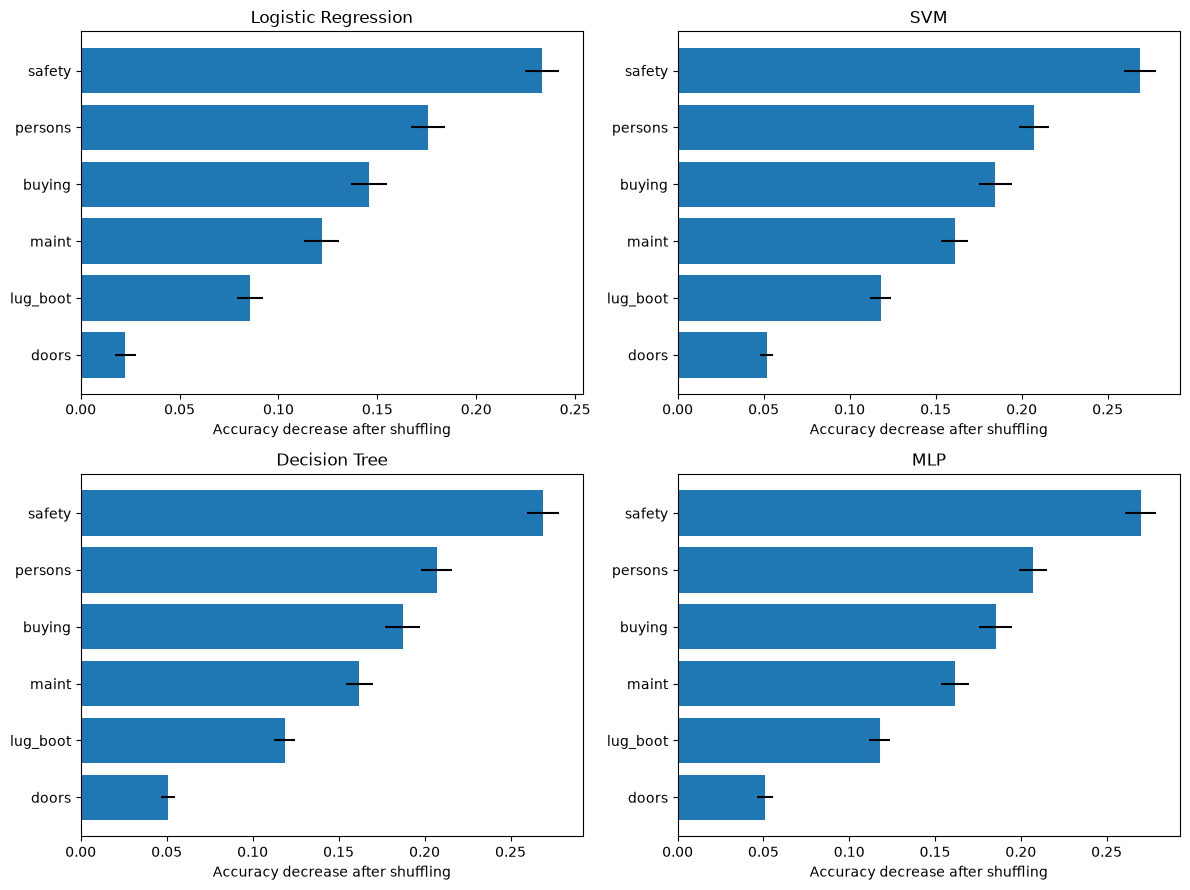

,Model,Feature,Mean accuracy decrease,Std. dev.
0,Logistic Regression,safety,0.233205,0.008707
1,Logistic Regression,persons,0.175515,0.008645
2,Logistic Regression,buying,0.145656,0.009114
3,Logistic Regression,maint,0.121815,0.008925
4,Logistic Regression,lug_boot,0.085586,0.006543
5,Logistic Regression,doors,0.022619,0.005148
6,SVM,safety,0.268887,0.009230
7,SVM,persons,0.207143,0.008574
8,SVM,buying,0.184717,0.009580
9,SVM,maint,0.161165,0.007871


In [12]:
models_for_importance = best_estimators

all_importances = []
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, pipeline) in zip(axes.flat, models_for_importance.items()):
    importance = permutation_importance(
        pipeline, X_train, y_train,
        scoring="accuracy", n_repeats=30, random_state=42, n_jobs=-1
    )

    model_importance = pd.DataFrame({
        "Model": name,
        "Feature": X.columns,
        "Mean accuracy decrease": importance.importances_mean,
        "Std. dev.": importance.importances_std,
    }).sort_values("Mean accuracy decrease", ascending=False)
    all_importances.append(model_importance)

    plot_data = model_importance.sort_values("Mean accuracy decrease")
    ax.barh(
        plot_data["Feature"], plot_data["Mean accuracy decrease"],
        xerr=plot_data["Std. dev."]
    )
    ax.set_title(name)
    ax.set_xlabel("Accuracy decrease after shuffling")

plt.tight_layout()
plt.show()

importance_df = pd.concat(all_importances, ignore_index=True)
importance_df